In [7]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

### Exploring the Urban Atlas green areas satellite data 2021

In [8]:
# Load the Urban Atlas vector dataset
urban_atlas = gpd.read_file(
    "satellite_data/green_areas_berlin_2021.fgb"
)

# Inspect the first rows
display(urban_atlas)

,country,fua_name,fua_code,code_2021,class_2021,prod_date,identifier,perimeter,area,comment,geometry
0,DE,Berlin,DE001L1,12100,"Industrial, commercial, public, military and p...",2025-09,51635-DE001L1,219.507606,7.334914e+02,None,"MULTIPOLYGON (((4596813.648 3242136.711, 45968..."
1,DE,Berlin,DE001L1,31000,Forests,2025-09,78837-DE001L1,357.435620,2.683082e+03,None,"MULTIPOLYGON (((4596813.421 3242135.857, 45968..."
2,DE,Berlin,DE001L1,21000,Arable land (annual crops),2025-09,67587-DE001L1,1123.886919,1.108254e+04,None,"MULTIPOLYGON (((4596919.96 3242282.689, 459692..."
3,DE,Berlin,DE001L1,40000,Wetlands,2025-09,80820-DE001L1,1771.841643,2.631102e+04,None,"MULTIPOLYGON (((4598146.546 3244910.998, 45981..."
4,DE,Berlin,DE001L1,14130,Green urban areas (Unknown access conditions),2025-09,57771-DE001L1,595.046280,5.860310e+03,None,"MULTIPOLYGON (((4597880.083 3244293.858, 45978..."
...,...,...,...,...,...,...,...,...,...,...,...
82019,DE,Berlin,DE001L1,21000,Arable land (annual crops),2025-09,61908-DE001L1,3587.440642,3.901165e+05,None,"MULTIPOLYGON (((4495644.459 3223471.985, 44956..."
82020,DE,Berlin,DE001L1,21000,Arable land (annual crops),2025-09,61897-DE001L1,2992.220720,3.911024e+05,None,"MULTIPOLYGON (((4495252.887 3223879.162, 44952..."
82021,DE,Berlin,DE001L1,31000,Forests,2025-09,71537-DE001L1,1946.632835,1.646176e+05,None,"MULTIPOLYGON (((4494979.786 3223725.587, 44949..."
82022,DE,Berlin,DE001L1,12100,"Industrial, commercial, public, military and p...",2025-09,40380-DE001L1,575.961734,3.435174e+03,None,"MULTIPOLYGON (((4495090.819 3223453.015, 44951..."


In [9]:
print(urban_atlas.dtypes)

country            str
fua_name           str
fua_code           str
code_2021          str
class_2021         str
prod_date          str
identifier         str
perimeter      float64
area           float64
comment         object
geometry      geometry
dtype: object


In [10]:
# Check the dimensions
print("Shape:", urban_atlas.shape)

# Check column names
print("\nColumns:")
print(urban_atlas.columns.tolist())

# Check data types
print("\nData types:")
print(urban_atlas.dtypes)

# Check the coordinate reference system
print("\nCRS:", urban_atlas.crs)

# Check geometry types
print("\nGeometry types:")
print(urban_atlas.geom_type.value_counts())

Shape: (82024, 11)

Columns:
['country', 'fua_name', 'fua_code', 'code_2021', 'class_2021', 'prod_date', 'identifier', 'perimeter', 'area', 'comment', 'geometry']

Data types:
country            str
fua_name           str
fua_code           str
code_2021          str
class_2021         str
prod_date          str
identifier         str
perimeter      float64
area           float64
comment         object
geometry      geometry
dtype: object

CRS: EPSG:3035

Geometry types:
MultiPolygon    82024
Name: count, dtype: int64


In [11]:
# Count features and sum the reported area for each land-cover class
land_cover_summary = (
    urban_atlas
    .groupby(["code_2021", "class_2021"])
    .agg(
        feature_count=("class_2021", "size"),
        reported_area_sum=("area", "sum")
    )
    .reset_index()
    .sort_values("reported_area_sum", ascending=False)
)

# Display the largest classes first
display(land_cover_summary)

# Count the number of distinct land-cover classes
print("Number of land-cover classes:", urban_atlas["class_2021"].nunique())

,code_2021,class_2021,feature_count,reported_area_sum
22,31000,Forests,7658,3.420419e+09
19,21000,Arable land (annual crops),6028,2.304718e+09
20,23000,Pastures,3610,1.256547e+09
6,12100,"Industrial, commercial, public, military and p...",11635,3.947422e+08
1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,16104,3.174513e+08
2,11220,Discontinuous medium density urban fabric (S.L...,12847,2.997991e+08
26,50000,Water,1196,2.427134e+08
8,12220,Other roads and associated land,272,1.777483e+08
18,14200,Sports and leisure facilities,3989,1.213595e+08
15,14110,Green urban areas (Public access),3188,1.208760e+08


Number of land-cover classes: 27


In [12]:
# Inspect the area and perimeter values
print("Area statistics:")
display(urban_atlas["area"].describe())

print("\nPerimeter statistics:")
display(urban_atlas["perimeter"].describe())

# Calculate polygon areas directly from the geometries
urban_atlas["geometry_area"] = urban_atlas.geometry.area

print("\nGeometry area statistics:")
display(urban_atlas["geometry_area"].describe())

# Compare the reported area with the geometry-derived area
urban_atlas["area_ratio"] = (
    urban_atlas["geometry_area"] / urban_atlas["area"]
)

print("\nArea ratio statistics:")
display(urban_atlas["area_ratio"].describe())

Area statistics:


count    8.202400e+04
mean     1.105030e+05
std      9.131451e+05
min      1.884688e+00
25%      8.247338e+03
50%      1.705167e+04
75%      3.480489e+04
max      1.684609e+08
Name: area, dtype: float64


Perimeter statistics:


count    8.202400e+04
mean     1.726479e+03
std      1.427845e+05
min      7.487228e+00
25%      4.128157e+02
50%      6.298858e+02
75%      1.031970e+03
max      4.088260e+07
Name: perimeter, dtype: float64


Geometry area statistics:


count    8.202400e+04
mean     1.105030e+05
std      9.131451e+05
min      1.884688e+00
25%      8.247338e+03
50%      1.705167e+04
75%      3.480489e+04
max      1.684609e+08
Name: geometry_area, dtype: float64


Area ratio statistics:


count    82024.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: area_ratio, dtype: float64

In [13]:
# Aggregate polygon areas by land-cover class
land_cover_summary = (
    urban_atlas
    .groupby(["code_2021", "class_2021"])
    .agg(
        feature_count=("area", "count"),
        area_m2=("area", "sum")
    )
    .reset_index()
)

# Convert square metres into hectares
land_cover_summary["area_ha"] = (
    land_cover_summary["area_m2"] / 10000
)

# Calculate percentage of the total mapped area
total_area = land_cover_summary["area_m2"].sum()

land_cover_summary["area_percentage"] = (
    land_cover_summary["area_m2"] / total_area * 100
)

# Sort from largest to smallest area
land_cover_summary = land_cover_summary.sort_values(
    "area_percentage",
    ascending=False
)

display(land_cover_summary.round(2))

,code_2021,class_2021,feature_count,area_m2,area_ha,area_percentage
22,31000,Forests,7658,3.420419e+09,342041.90,37.74
19,21000,Arable land (annual crops),6028,2.304718e+09,230471.78,25.43
20,23000,Pastures,3610,1.256547e+09,125654.68,13.86
6,12100,"Industrial, commercial, public, military and p...",11635,3.947422e+08,39474.22,4.36
1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,16104,3.174513e+08,31745.13,3.50
2,11220,Discontinuous medium density urban fabric (S.L...,12847,2.997991e+08,29979.91,3.31
26,50000,Water,1196,2.427134e+08,24271.34,2.68
8,12220,Other roads and associated land,272,1.777483e+08,17774.83,1.96
18,14200,Sports and leisure facilities,3989,1.213595e+08,12135.95,1.34
15,14110,Green urban areas (Public access),3188,1.208760e+08,12087.60,1.33


In [14]:
# Get the geographic extent of the dataset
print("Bounding box:")
print(urban_atlas.total_bounds)

Bounding box:
[4487400.4084 3211307.0038 4609936.8907 3345192.6136]


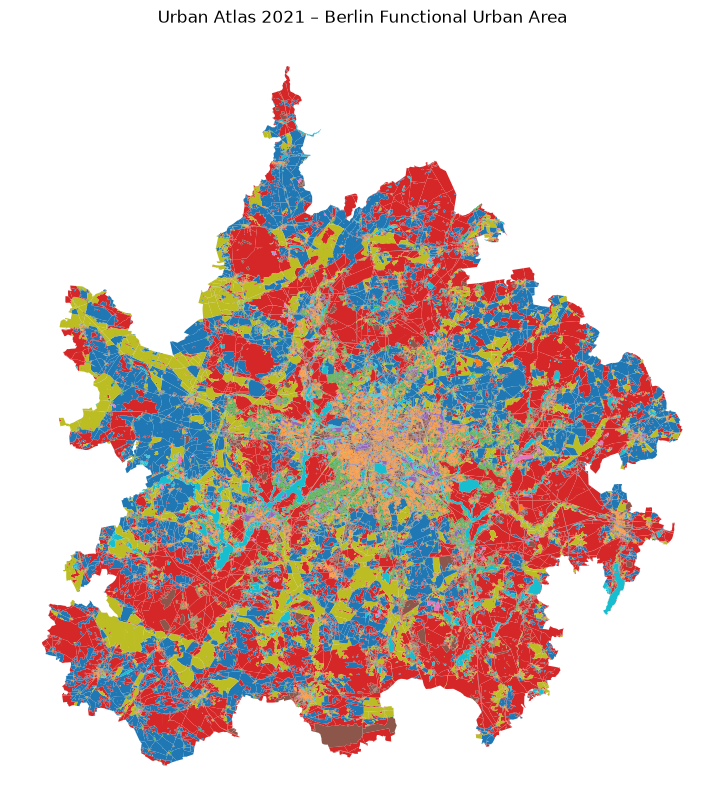

In [15]:
# Plot the land-cover polygons
urban_atlas.plot(
    figsize=(10, 10),
    column="class_2021",
    legend=False
)

plt.title("Urban Atlas 2021 – Berlin Functional Urban Area")
plt.axis("off")
plt.show()

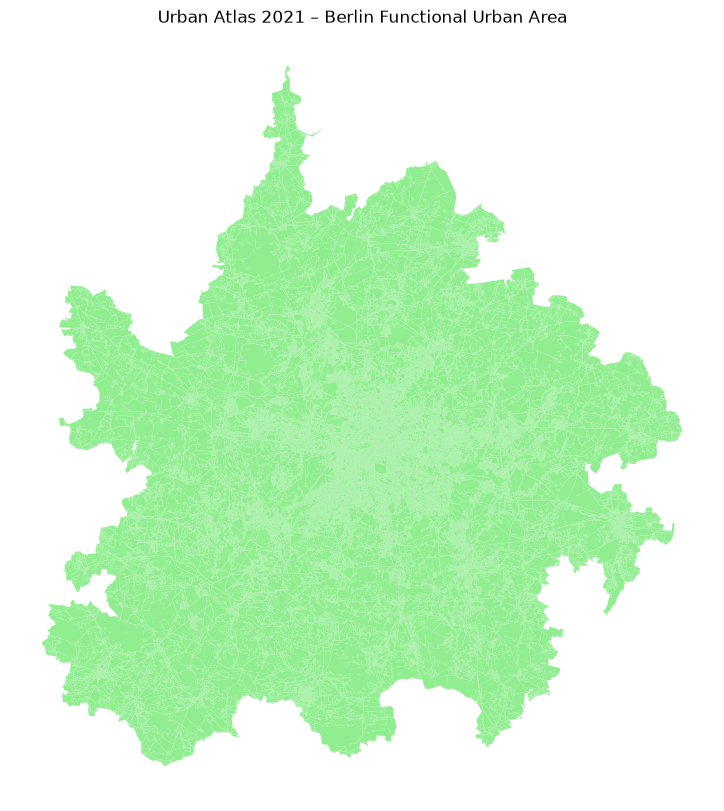

In [16]:
# Plot the Urban Atlas polygons
ax = urban_atlas.plot(
    figsize=(10, 10),
    color="lightgreen",
    edgecolor="none"
)

ax.set_title("Urban Atlas 2021 – Berlin Functional Urban Area")
ax.set_axis_off()

plt.show()

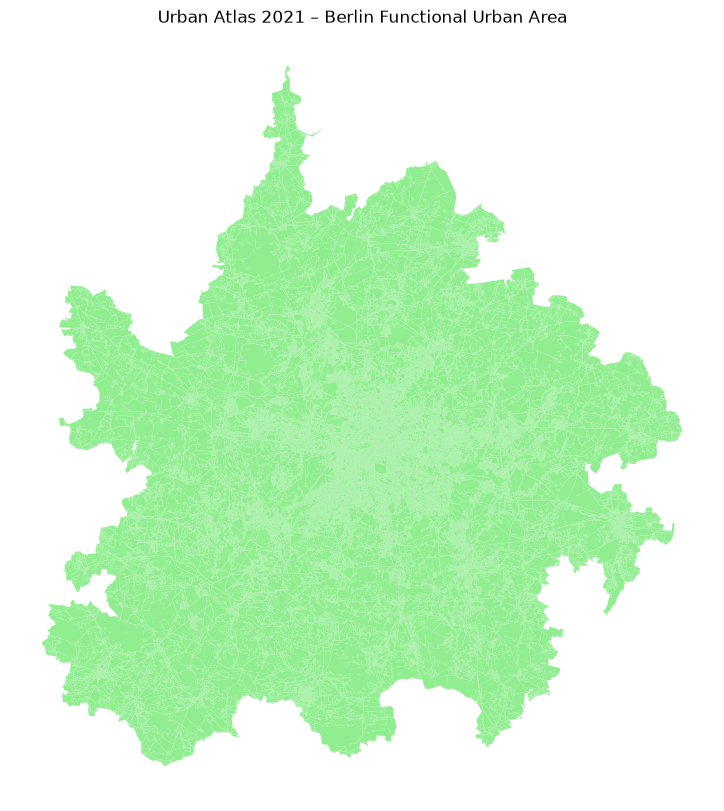

In [17]:
# Plot the dataset
ax = urban_atlas.plot(
    figsize=(10, 10),
    color="lightgreen",
    edgecolor="none"
)

ax.set_title("Urban Atlas 2021 – Berlin Functional Urban Area")
ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [18]:
# Transform the dataset's bounding box to longitude/latitude
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:3035",
    "EPSG:4326",
    always_xy=True
)

min_x, min_y, max_x, max_y = urban_atlas.total_bounds

print("Minimum longitude/latitude:", transformer.transform(min_x, min_y))
print("Maximum longitude/latitude:", transformer.transform(max_x, max_y))

Minimum longitude/latitude: (12.422715155003235, 51.98689199789101)
Maximum longitude/latitude: (14.32006809208746, 53.13766113165156)


In [19]:
# Load the LOR CSV file
lor = pd.read_csv(
    "satellite_data/berlin_lor_2021.csv",
    sep=None,
    engine="python"
)

# Inspect its structure
print("Shape:", lor.shape)

print("\nColumns:")
print(lor.columns.tolist())

print("\nData types:")
print(lor.dtypes)

# Display the first five rows
display(lor.head())

Shape: (143, 7)

Columns:
['bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt', 'stand']

Data types:
bzr_id        int64
bzr_name        str
pgr_id        int64
pgr_name        str
bez             str
finhalt     float64
stand           str
dtype: object


,bzr_id,bzr_name,pgr_id,pgr_name,bez,finhalt,stand
0,11001,Tiergarten Süd,110,Zentrum,01 - Mitte,5.172481e+06,01.12.2021
1,11002,Regierungsviertel,110,Zentrum,01 - Mitte,2.695511e+06,01.01.2021
2,11003,Alexanderplatz,110,Zentrum,01 - Mitte,6.228825e+06,01.01.2021
3,11004,Brunnenstraße Süd,110,Zentrum,01 - Mitte,1.755196e+06,01.01.2021
4,12005,Moabit West,120,Moabit,01 - Mitte,4.305047e+06,01.01.2021


In [14]:
# Check the number of unique neighbourhood IDs
print("Total rows:", len(lor))
print("Unique BZR IDs:", lor["bzr_id"].nunique())

# Check for duplicate IDs
print("Duplicate BZR IDs:", lor["bzr_id"].duplicated().sum())

# Count neighbourhoods per administrative district
display(
    lor.groupby("bez")["bzr_id"]
    .nunique()
    .sort_values(ascending=False)
)

Total rows: 143
Unique BZR IDs: 143
Duplicate BZR IDs: 0


bez
09 - Treptow-Köpenick              20
03 - Pankow                        16
07 - Tempelhof-Schöneberg          15
11 - Lichtenberg                   13
12 - Reinickendorf                 12
08 - Neukölln                      12
04 - Charlottenburg-Wilmersdorf    11
01 - Mitte                         10
10 - Marzahn-Hellersdorf            9
05 - Spandau                        9
02 - Friedrichshain-Kreuzberg       8
06 - Steglitz-Zehlendorf            8
Name: bzr_id, dtype: int64

In [15]:
# Load the LOR geographical boundaries
lor_boundaries = gpd.read_file(
    "satellite_data/berlin_lor_2021.geojson"
)

# Display the first five rows
display(lor_boundaries.head())

,id,bzr_id,bzr_name,pgr_id,pgr_name,bez,finhalt,stand,geometry
0,b_lor_bzr_2021.011001,011001,Tiergarten Süd,0110,Zentrum,01 - Mitte,5.172481e+06,01.12.2021,"MULTIPOLYGON (((13.33601 52.51379, 13.33587 52..."
1,b_lor_bzr_2021.011002,011002,Regierungsviertel,0110,Zentrum,01 - Mitte,2.695511e+06,01.01.2021,"MULTIPOLYGON (((13.3765 52.51602, 13.37651 52...."
2,b_lor_bzr_2021.011003,011003,Alexanderplatz,0110,Zentrum,01 - Mitte,6.228825e+06,01.01.2021,"MULTIPOLYGON (((13.37357 52.52788, 13.37364 52..."
3,b_lor_bzr_2021.011004,011004,Brunnenstraße Süd,0110,Zentrum,01 - Mitte,1.755196e+06,01.01.2021,"MULTIPOLYGON (((13.39586 52.53809, 13.39569 52..."
4,b_lor_bzr_2021.012005,012005,Moabit West,0120,Moabit,01 - Mitte,4.305047e+06,01.01.2021,"MULTIPOLYGON (((13.33422 52.51677, 13.33431 52..."


In [16]:
# Inspect the dataset structure
print("Shape:", lor_boundaries.shape)

print("\nColumns:")
print(lor_boundaries.columns.tolist())

print("\nCRS:", lor_boundaries.crs)

print("\nGeometry types:")
print(lor_boundaries.geom_type.value_counts())

Shape: (143, 9)

Columns:
['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt', 'stand', 'geometry']

CRS: EPSG:4326

Geometry types:
MultiPolygon    143
Name: count, dtype: int64


In [17]:
# Check for duplicate region IDs
print("Duplicate bzr_id values:", lor_boundaries["bzr_id"].duplicated().sum())

# Check for missing geometries
print("Missing geometries:", lor_boundaries.geometry.isna().sum())

# Check whether geometries are valid
print("Invalid geometries:", (~lor_boundaries.geometry.is_valid).sum())

# Reproject to a coordinate system measured in metres
lor_projected = lor_boundaries.to_crs(epsg=3035)

# Calculate polygon area in square metres
lor_projected["geometry_area_m2"] = lor_projected.geometry.area

# Compare calculated area with finhalt
lor_projected["area_difference_m2"] = (
    lor_projected["geometry_area_m2"] - lor_projected["finhalt"]
)

display(
    lor_projected[
        ["bzr_id", "bzr_name", "finhalt",
         "geometry_area_m2", "area_difference_m2"]
    ].head()
)

print(
    "Mean absolute area difference:",
    lor_projected["area_difference_m2"].abs().mean()
)

Duplicate bzr_id values: 0
Missing geometries: 0
Invalid geometries: 0


,bzr_id,bzr_name,finhalt,geometry_area_m2,area_difference_m2
0,011001,Tiergarten Süd,5.172481e+06,5.172416e+06,-64.856908
1,011002,Regierungsviertel,2.695511e+06,2.695472e+06,-39.011780
2,011003,Alexanderplatz,6.228825e+06,6.228747e+06,-77.962426
3,011004,Brunnenstraße Süd,1.755196e+06,1.755172e+06,-23.873015
4,012005,Moabit West,4.305047e+06,4.304979e+06,-67.921646


Mean absolute area difference: 88.7013023153633


In [18]:
# Reproject LOR boundaries to a metric CRS
lor_metric = lor_boundaries.to_crs(epsg=25833)

# Calculate total area
lor_total_area_km2 = lor_metric.geometry.area.sum() / 1_000_000

print("Total LOR area (km²):", round(lor_total_area_km2, 2))

# Check the number of administrative districts
print("Number of districts:", lor_boundaries["bez"].nunique())

# Check how many regions belong to each district
display(
    lor_boundaries.groupby("bez")
    .size()
    .reset_index(name="region_count")
    .sort_values("bez")
)

Total LOR area (km²): 890.67
Number of districts: 12


,bez,region_count
0,01 - Mitte,10
1,02 - Friedrichshain-Kreuzberg,8
2,03 - Pankow,16
3,04 - Charlottenburg-Wilmersdorf,11
4,05 - Spandau,9
5,06 - Steglitz-Zehlendorf,8
6,07 - Tempelhof-Schöneberg,15
7,08 - Neukölln,12
8,09 - Treptow-Köpenick,20
9,10 - Marzahn-Hellersdorf,9


In [19]:
# Combine all LOR polygons into one geometry
lor_union = lor_metric.geometry.union_all()

# Compare the sum of individual areas with the union area
sum_area_km2 = lor_metric.geometry.area.sum() / 1_000_000
union_area_km2 = lor_union.area / 1_000_000

overlap_area_km2 = sum_area_km2 - union_area_km2

print("Sum of individual areas:", round(sum_area_km2, 4), "km²")
print("Union area:", round(union_area_km2, 4), "km²")
print("Difference:", round(overlap_area_km2, 8), "km²")

Sum of individual areas: 890.6667 km²
Union area: 890.6667 km²
Difference: 0.0 km²


In [20]:
# Get the bounding box of the combined LOR geometry
minx, miny, maxx, maxy = lor_metric.total_bounds

print("West:", minx)
print("South:", miny)
print("East:", maxx)
print("North:", maxy)

West: 370000.82509456767
South: 5799520.664258519
East: 415786.5530374588
North: 5837259.27447665


In [21]:
# Reproject Urban Atlas to the same CRS as the LOR boundaries
urban_atlas_metric = urban_atlas.to_crs(epsg=25833)

# Inspect its geographic extent
minx, miny, maxx, maxy = urban_atlas_metric.total_bounds

print("West:", minx)
print("South:", miny)
print("East:", maxx)
print("North:", maxy)

print("\nCRS:", urban_atlas_metric.crs)

West: 324658.5387759687
South: 5760327.014634713
East: 449698.4275472523
North: 5893027.059501999

CRS: EPSG:25833


In [22]:
# Check that both datasets use the same CRS
print("LOR CRS:", lor_metric.crs)
print("Urban Atlas CRS:", urban_atlas_metric.crs)

# Check geometry validity
print("LOR invalid geometries:",
      (~lor_metric.geometry.is_valid).sum())

print("Urban Atlas invalid geometries:",
      (~urban_atlas_metric.geometry.is_valid).sum())

LOR CRS: EPSG:25833
Urban Atlas CRS: EPSG:25833
LOR invalid geometries: 0
Urban Atlas invalid geometries: 13


In [23]:
# Find invalid Urban Atlas geometries
invalid_ua = urban_atlas_metric[
    ~urban_atlas_metric.geometry.is_valid
].copy()

print("Invalid records:", len(invalid_ua))

# Inspect their attributes
display(
    invalid_ua[
        ["country", "fua_name", "code_2021", "class_2021", "area"]
    ]
)

Invalid records: 13


,country,fua_name,code_2021,class_2021,area
95,DE,Berlin,31000,Forests,2254.186209
28199,DE,Berlin,50000,Water,6390.682607
31589,DE,Berlin,11220,Discontinuous medium density urban fabric (S.L...,76185.161803
31590,DE,Berlin,50000,Water,3560.429631
31629,DE,Berlin,50000,Water,1780.331986
32114,DE,Berlin,21000,Arable land (annual crops),4465.380391
52752,DE,Berlin,14130,Green urban areas (Unknown access conditions),3543.339775
52759,DE,Berlin,21000,Arable land (annual crops),1983.978771
53098,DE,Berlin,50000,Water,2627.547638
58302,DE,Berlin,21000,Arable land (annual crops),2479.544137


In [24]:
# Identify the reason each geometry is invalid
invalid_ua["invalid_reason"] = (
    invalid_ua.geometry.is_valid_reason()
)

display(
    invalid_ua[
        ["code_2021", "class_2021", "invalid_reason"]
    ]
)

,code_2021,class_2021,invalid_reason
95,31000,Forests,Self-intersection[420067.730043287 5789048.364...
28199,50000,Water,Self-intersection[444683.196158839 5796863.524...
31589,11220,Discontinuous medium density urban fabric (S.L...,Self-intersection[412684.525345282 5863197.273...
31590,50000,Water,Self-intersection[412733.917927405 5863239.698...
31629,50000,Water,Self-intersection[413450.648352472 5863724.664...
32114,21000,Arable land (annual crops),Self-intersection[392194.909373633 5865329.994...
52752,14130,Green urban areas (Unknown access conditions),Self-intersection[381894.098300985 5879568.281...
52759,21000,Arable land (annual crops),Self-intersection[383972.929023113 5879918.188...
53098,50000,Water,Self-intersection[372086.705269001 5870645.159...
58302,21000,Arable land (annual crops),Self-intersection[346598.790853789 5814188.702...


In [25]:
# Create a working copy
urban_atlas_repaired = urban_atlas_metric.copy()

# Repair invalid geometries
invalid_mask = ~urban_atlas_repaired.geometry.is_valid

urban_atlas_repaired.loc[invalid_mask, "geometry"] = (
    urban_atlas_repaired.loc[invalid_mask, "geometry"].make_valid()
)

# Check geometry validity again
print(
    "Invalid geometries after repair:",
    (~urban_atlas_repaired.geometry.is_valid).sum()
)

# Check geometry types after repair
print("\nGeometry types:")
print(urban_atlas_repaired.geom_type.value_counts())

Invalid geometries after repair: 0

Geometry types:
MultiPolygon    82024
Name: count, dtype: int64


In [26]:
# Calculate original and repaired geometry areas
original_areas = urban_atlas_metric.geometry.area
repaired_areas = urban_atlas_repaired.geometry.area

# Calculate area differences
area_comparison = pd.DataFrame({
    "original_area_m2": original_areas,
    "repaired_area_m2": repaired_areas
})

area_comparison["difference_m2"] = (
    area_comparison["repaired_area_m2"]
    - area_comparison["original_area_m2"]
)

# Inspect only the 13 repaired records
display(
    area_comparison.loc[invalid_mask].round(3)
)

print(
    "Maximum absolute area difference:",
    round(area_comparison.loc[invalid_mask, "difference_m2"].abs().max(), 3),
    "m²"
)

,original_area_m2,repaired_area_m2,difference_m2
95,2252.737,2252.737,0.000
28199,6386.053,6386.053,0.000
31589,76138.431,76138.431,0.000
31590,3558.245,3558.245,0.000
31629,1779.236,1779.236,0.000
32114,4463.085,4463.085,0.000
52752,3541.714,3541.714,0.000
52759,1983.048,1983.048,0.000
53098,2626.502,2626.502,0.000
58302,2478.991,2478.991,0.000


Maximum absolute area difference: 0.001 m²


In [27]:
# Clip Urban Atlas to the combined LOR boundaries
urban_atlas_lor = gpd.clip(
    urban_atlas_repaired,
    lor_union
)

# Inspect the result
print("Shape:", urban_atlas_lor.shape)

print("\nCRS:", urban_atlas_lor.crs)

print("\nGeometry types:")
print(urban_atlas_lor.geom_type.value_counts())

print(
    "\nInvalid geometries:",
    (~urban_atlas_lor.geometry.is_valid).sum()
)

Shape: (21921, 13)

CRS: EPSG:25833

Geometry types:
Polygon         21828
MultiPolygon       93
Name: count, dtype: int64

Invalid geometries: 0


In [28]:
# Calculate total area of clipped Urban Atlas features
clipped_area_km2 = (
    urban_atlas_lor.geometry.area.sum() / 1_000_000
)

# Calculate total area of LOR boundaries
lor_area_km2 = (
    lor_metric.geometry.area.sum() / 1_000_000
)

print("Clipped Urban Atlas area:", round(clipped_area_km2, 2), "km²")
print("Total LOR area:", round(lor_area_km2, 2), "km²")

print(
    "Difference:",
    round(lor_area_km2 - clipped_area_km2, 2),
    "km²"
)

Clipped Urban Atlas area: 890.67 km²
Total LOR area: 890.67 km²
Difference: -0.0 km²


In [29]:
# Combine all clipped Urban Atlas geometries
ua_union = urban_atlas_lor.geometry.union_all()

# Check for areas missing from Urban Atlas
missing_area_km2 = (
    lor_union.difference(ua_union).area / 1_000_000
)

# Check for Urban Atlas areas outside the LOR boundaries
outside_area_km2 = (
    ua_union.difference(lor_union).area / 1_000_000
)

# Check for overlaps between Urban Atlas features
ua_overlap_km2 = (
    urban_atlas_lor.geometry.area.sum()
    - ua_union.area
) / 1_000_000

print("Missing LOR area:", missing_area_km2, "km²")
print("Area outside LOR:", outside_area_km2, "km²")
print("Overlapping Urban Atlas area:", ua_overlap_km2, "km²")

Missing LOR area: 2.082610223829094e-10 km²
Area outside LOR: 1.3052374017779796e-12 km²
Overlapping Urban Atlas area: 2.1278858184814452e-10 km²


In [30]:
# Intersect Urban Atlas polygons with individual LOR regions
urban_atlas_by_lor = gpd.overlay(
    urban_atlas_lor,
    lor_metric[["bzr_id", "bzr_name", "bez", "geometry"]],
    how="intersection",
    keep_geom_type=False
)

# Inspect the resulting dataset
print("Shape:", urban_atlas_by_lor.shape)

print("\nCRS:", urban_atlas_by_lor.crs)

print("\nInvalid geometries:",
      (~urban_atlas_by_lor.geometry.is_valid).sum())

print("\nNumber of neighbourhoods:",
      urban_atlas_by_lor["bzr_id"].nunique())

display(
    urban_atlas_by_lor[
        ["bzr_id", "bzr_name", "class_2021", "geometry"]
    ].head()
)

Shape: (24961, 16)

CRS: EPSG:25833

Invalid geometries: 0

Number of neighbourhoods: 143


,bzr_id,bzr_name,class_2021,geometry
0,093012,Schmöckwitz,Discontinuous medium density urban fabric (S.L...,"POLYGON ((407909.572 5799818.428, 407870.608 5..."
1,093012,Schmöckwitz,Discontinuous medium density urban fabric (S.L...,"POLYGON ((407700.715 5799778.449, 407691.455 5..."
2,093012,Schmöckwitz,Land without current use,"POLYGON ((407817.135 5800067.953, 407817.141 5..."
3,093012,Schmöckwitz,Discontinuous medium density urban fabric (S.L...,"POLYGON ((407752.309 5800106.532, 407753.41 58..."
4,093012,Schmöckwitz,Forests,"POLYGON ((407743.253 5800419.753, 407744.292 5..."


In [31]:
# Calculate area in square metres
urban_atlas_by_lor["area_m2"] = (
    urban_atlas_by_lor.geometry.area
)

# Convert area to hectares
urban_atlas_by_lor["area_ha"] = (
    urban_atlas_by_lor["area_m2"] / 10_000
)

# Aggregate by neighbourhood and land-cover class
land_cover_by_lor = (
    urban_atlas_by_lor
    .groupby(
        ["bzr_id", "bzr_name", "bez", "class_2021"],
        as_index=False
    )
    .agg(
        area_m2=("area_m2", "sum"),
        area_ha=("area_ha", "sum")
    )
)

print("Shape:", land_cover_by_lor.shape)

print("\nNumber of neighbourhoods:",
      land_cover_by_lor["bzr_id"].nunique())

display(land_cover_by_lor.head(10))

Shape: (1679, 6)

Number of neighbourhoods: 143


,bzr_id,bzr_name,bez,class_2021,area_m2,area_ha
0,011001,Tiergarten Süd,01 - Mitte,Continuous urban fabric (S.L. : > 80%),7.278643e+05,72.786430
1,011001,Tiergarten Süd,01 - Mitte,Discontinuous dense urban fabric (S.L. : 50% -...,1.251207e+05,12.512074
2,011001,Tiergarten Süd,01 - Mitte,Discontinuous medium density urban fabric (S.L...,4.075514e+03,0.407551
3,011001,Tiergarten Süd,01 - Mitte,Green urban areas (Public access),2.507192e+06,250.719194
4,011001,Tiergarten Süd,01 - Mitte,"Industrial, commercial, public, military and p...",1.147780e+06,114.778013
5,011001,Tiergarten Süd,01 - Mitte,Other roads and associated land,4.877955e+05,48.779548
6,011001,Tiergarten Süd,01 - Mitte,Railways and associated land,8.063516e+03,0.806352
7,011001,Tiergarten Süd,01 - Mitte,Water,1.619634e+05,16.196339
8,011002,Regierungsviertel,01 - Mitte,Continuous urban fabric (S.L. : > 80%),9.232676e+05,92.326760
9,011002,Regierungsviertel,01 - Mitte,Discontinuous dense urban fabric (S.L. : 50% -...,8.321504e+04,8.321504


In [32]:
# Calculate total land-cover area per neighbourhood
neighbourhood_totals = (
    land_cover_by_lor
    .groupby("bzr_id", as_index=False)
    .agg(total_land_cover_m2=("area_m2", "sum"))
)

# Add neighbourhood totals to the land-cover table
land_cover_by_lor = land_cover_by_lor.merge(
    neighbourhood_totals,
    on="bzr_id",
    how="left"
)

# Calculate percentage of each neighbourhood
land_cover_by_lor["area_percentage"] = (
    land_cover_by_lor["area_m2"]
    / land_cover_by_lor["total_land_cover_m2"]
    * 100
)

# Inspect the results
display(
    land_cover_by_lor[
        ["bzr_name", "class_2021", "area_ha", "area_percentage"]
    ].head(15).round(2)
)

,bzr_name,class_2021,area_ha,area_percentage
0,Tiergarten Süd,Continuous urban fabric (S.L. : > 80%),72.79,14.08
1,Tiergarten Süd,Discontinuous dense urban fabric (S.L. : 50% -...,12.51,2.42
2,Tiergarten Süd,Discontinuous medium density urban fabric (S.L...,0.41,0.08
3,Tiergarten Süd,Green urban areas (Public access),250.72,48.50
4,Tiergarten Süd,"Industrial, commercial, public, military and p...",114.78,22.20
5,Tiergarten Süd,Other roads and associated land,48.78,9.44
6,Tiergarten Süd,Railways and associated land,0.81,0.16
7,Tiergarten Süd,Water,16.20,3.13
8,Regierungsviertel,Continuous urban fabric (S.L. : > 80%),92.33,34.27
9,Regierungsviertel,Discontinuous dense urban fabric (S.L. : 50% -...,8.32,3.09


In [33]:
# Check percentage totals per neighbourhood
percentage_check = (
    land_cover_by_lor
    .groupby("bzr_id", as_index=False)
    .agg(
        percentage_sum=("area_percentage", "sum")
    )
)

# Get actual LOR polygon areas
lor_area_check = lor_metric[["bzr_id", "geometry"]].copy()

lor_area_check["lor_area_m2"] = (
    lor_area_check.geometry.area
)

# Merge the two area measurements
area_check = neighbourhood_totals.merge(
    lor_area_check[["bzr_id", "lor_area_m2"]],
    on="bzr_id",
    how="left"
)

# Calculate differences
area_check["area_difference_m2"] = (
    area_check["total_land_cover_m2"]
    - area_check["lor_area_m2"]
)

# Display validation results
print("Percentage totals:")
print(percentage_check["percentage_sum"].describe().round(6))

print("\nArea differences (m²):")
print(area_check["area_difference_m2"].abs().describe().round(3))

print(
    "\nNeighbourhoods with area difference above 1 m²:",
    (area_check["area_difference_m2"].abs() > 1).sum()
)

Percentage totals:
count    143.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: percentage_sum, dtype: float64

Area differences (m²):
count    143.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: area_difference_m2, dtype: float64

Neighbourhoods with area difference above 1 m²: 0


In [34]:
# Convert land-cover classes into separate columns
land_cover_wide = (
    land_cover_by_lor
    .pivot_table(
        index=["bzr_id", "bzr_name", "bez"],
        columns="class_2021",
        values="area_percentage",
        fill_value=0
    )
    .reset_index()
)

# Remove the column index name
land_cover_wide.columns.name = None

# Inspect the result
print("Shape:", land_cover_wide.shape)

print("\nNumber of neighbourhoods:",
      land_cover_wide["bzr_id"].nunique())

display(land_cover_wide.head())

Shape: (143, 30)

Number of neighbourhoods: 143


,bzr_id,bzr_name,bez,Airports,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Continuous urban fabric (S.L. : > 80%),Discontinuous dense urban fabric (S.L. : 50% - 80%),Discontinuous low density urban fabric (S.L. : 10% - 30%),...,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Other roads and associated land,Pastures,Port areas,Railways and associated land,Sports and leisure facilities,Water,Wetlands
0,011001,Tiergarten Süd,01 - Mitte,0.0,0.0,0.0,0.0,14.079008,2.420198,0.000000,...,0.000000,0.0,0.0,9.435380,0.0,0.000000,0.155972,0.000000,3.132842,0.0
1,011002,Regierungsviertel,01 - Mitte,0.0,0.0,0.0,0.0,34.269916,3.088782,0.000000,...,0.000000,0.0,0.0,13.626306,0.0,0.000000,0.880027,0.658809,1.967732,0.0
2,011003,Alexanderplatz,01 - Mitte,0.0,0.0,0.0,0.0,24.783306,9.926750,0.060949,...,0.000000,0.0,0.0,13.139817,0.0,0.151716,1.221047,0.590537,5.733040,0.0
3,011004,Brunnenstraße Süd,01 - Mitte,0.0,0.0,0.0,0.0,49.495315,12.144431,0.000000,...,1.003718,0.0,0.0,6.439646,0.0,0.000000,0.350215,0.634204,0.000000,0.0
4,012005,Moabit West,01 - Mitte,0.0,0.0,0.0,0.0,21.816611,7.645850,0.000000,...,0.213724,0.0,0.0,8.507764,0.0,7.275991,7.875844,1.176712,12.673263,0.0


In [35]:
# Check the number of neighbourhoods and columns
print("Shape:", land_cover_wide.shape)
print("Unique neighbourhoods:", land_cover_wide["bzr_id"].nunique())

# Select only the land-cover percentage columns
land_cover_columns = land_cover_wide.columns[3:]

# Check percentage totals for each neighbourhood
land_cover_wide["percentage_sum"] = (
    land_cover_wide[land_cover_columns].sum(axis=1)
)

print(land_cover_wide["percentage_sum"].describe())

# Check whether any neighbourhood differs from 100%
print(
    "Neighbourhoods not summing to 100%:",
    (land_cover_wide["percentage_sum"].sub(100).abs() > 0.01).sum()
)

Shape: (143, 30)
Unique neighbourhoods: 143
count    1.430000e+02
mean     1.000000e+02
std      1.073294e-14
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: percentage_sum, dtype: float64
Neighbourhoods not summing to 100%: 0


In [36]:
# List all land-cover class columns
for column in land_cover_columns:
    print(column)

Airports
Arable land (annual crops)
Complex and mixed cultivation patterns
Construction sites
Continuous urban fabric (S.L. : > 80%)
Discontinuous dense urban fabric (S.L. : 50% -  80%)
Discontinuous low density urban fabric (S.L. : 10% - 30%)
Discontinuous medium density urban fabric (S.L. : 30% - 50%)
Discontinuous very low density urban fabric (S.L. : < 10%)
Fast transit roads and associated land
Forests
Green urban areas (Private access)
Green urban areas (Public access)
Green urban areas (Unknown access conditions)
Herbaceous vegetation associations (natural grassland, moors...)
Industrial, commercial, public, military and private units
Isolated structures
Land without current use
Mineral extraction and dump sites
Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)
Other roads and associated land
Pastures
Port areas
Railways and associated land
Sports and leisure facilities
Water
Wetlands


In [37]:
# Define the Urban Atlas classes belonging to each indicator
land_cover_groups = {
    "urban_fabric": [
        "Continuous urban fabric (S.L. : > 80%)",
        "Discontinuous dense urban fabric (S.L. : 50% -  80%)",
        "Discontinuous medium density urban fabric (S.L. : 30% - 50%)",
        "Discontinuous low density urban fabric (S.L. : 10% - 30%)",
        "Discontinuous very low density urban fabric (S.L. : < 10%)"
    ],

    "green_natural": [
        "Forests",
        "Green urban areas (Private access)",
        "Green urban areas (Public access)",
        "Green urban areas (Unknown access conditions)",
        "Herbaceous vegetation associations (natural grassland, moors...)",
        "Pastures"
    ],

    "industrial_commercial": [
        "Industrial, commercial, public, military and private units"
    ],

    "transport_infrastructure": [
        "Airports",
        "Fast transit roads and associated land",
        "Other roads and associated land",
        "Railways and associated land",
        "Port areas"
    ],

    "water_wetlands": [
        "Water",
        "Wetlands"
    ]
}

# Keep neighbourhood identifiers
land_cover_indicators = land_cover_wide[
    ["bzr_id", "bzr_name", "bez"]
].copy()

# Calculate the percentage for each indicator
for indicator, classes in land_cover_groups.items():
    land_cover_indicators[indicator] = (
        land_cover_wide[classes].sum(axis=1)
    )

# Display the result
display(land_cover_indicators.head())

,bzr_id,bzr_name,bez,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands
0,011001,Tiergarten Süd,01 - Mitte,16.578038,48.496369,22.201399,9.591352,3.132842
1,011002,Regierungsviertel,01 - Mitte,37.358698,4.922988,40.585440,14.506333,1.967732
2,011003,Alexanderplatz,01 - Mitte,38.662168,4.914470,35.587205,14.512580,5.733040
3,011004,Brunnenstraße Süd,01 - Mitte,61.910045,16.318114,13.344057,6.789861,0.000000
4,012005,Moabit West,01 - Mitte,29.973623,1.233878,30.942525,23.786275,12.673263


In [38]:
# Identify classes not included in the five indicators
grouped_classes = [
    land_class
    for classes in land_cover_groups.values()
    for land_class in classes
]

remaining_classes = [
    column
    for column in land_cover_columns
    if column not in grouped_classes
]

print("Remaining classes:")
for column in remaining_classes:
    print(column)

# Calculate the percentage represented by the remaining classes
land_cover_indicators["other_land_cover"] = (
    land_cover_wide[remaining_classes].sum(axis=1)
)

# Check whether all categories account for 100%
indicator_columns = [
    "urban_fabric",
    "green_natural",
    "industrial_commercial",
    "transport_infrastructure",
    "water_wetlands",
    "other_land_cover"
]

land_cover_indicators["percentage_sum"] = (
    land_cover_indicators[indicator_columns].sum(axis=1)
)

print("\nPercentage sum validation:")
print(land_cover_indicators["percentage_sum"].describe())

print(
    "\nNeighbourhoods not summing to 100%:",
    (
        land_cover_indicators["percentage_sum"]
        .sub(100)
        .abs()
        .gt(0.01)
        .sum()
    )
)

Remaining classes:
Arable land (annual crops)
Complex and mixed cultivation patterns
Construction sites
Isolated structures
Land without current use
Mineral extraction and dump sites
Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)
Sports and leisure facilities

Percentage sum validation:
count    1.430000e+02
mean     1.000000e+02
std      1.180563e-14
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: percentage_sum, dtype: float64

Neighbourhoods not summing to 100%: 0


In [39]:
# Combine grouped indicators with the remaining original classes
land_cover_final = land_cover_indicators[
    ["bzr_id", "bzr_name", "bez"]
    + list(land_cover_groups.keys())
].copy()

for column in remaining_classes:
    land_cover_final[column] = land_cover_wide[column]

# Check the final dataset
print("Shape:", land_cover_final.shape)
print("Unique neighbourhoods:", land_cover_final["bzr_id"].nunique())

display(land_cover_final.head())

Shape: (143, 16)
Unique neighbourhoods: 143


,bzr_id,bzr_name,bez,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Isolated structures,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Sports and leisure facilities
0,011001,Tiergarten Süd,01 - Mitte,16.578038,48.496369,22.201399,9.591352,3.132842,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000
1,011002,Regierungsviertel,01 - Mitte,37.358698,4.922988,40.585440,14.506333,1.967732,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.658809
2,011003,Alexanderplatz,01 - Mitte,38.662168,4.914470,35.587205,14.512580,5.733040,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.590537
3,011004,Brunnenstraße Süd,01 - Mitte,61.910045,16.318114,13.344057,6.789861,0.000000,0.0,0.0,0.0,0.0,1.003718,0.0,0.0,0.634204
4,012005,Moabit West,01 - Mitte,29.973623,1.233878,30.942525,23.786275,12.673263,0.0,0.0,0.0,0.0,0.213724,0.0,0.0,1.176712


In [40]:
# Save the final land-cover indicators
land_cover_final.to_csv(
    "berlin_land_cover_by_neighbourhood.csv",
    index=False
)

In [41]:
# Merge neighbourhood geometries with land-cover indicators
lor_land_cover = lor_metric.merge(
    land_cover_final,
    on=["bzr_id", "bzr_name", "bez"],
    how="left"
)

In [42]:
land_cover_final.head()

#it could be worth adding ratios, for example areas affected by industry vs transport-infrastructure
# also, consider certain patterns like areas with more green areas have lower temperatures? do industrial areas affect air quality?

,bzr_id,bzr_name,bez,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Isolated structures,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Sports and leisure facilities
0,011001,Tiergarten Süd,01 - Mitte,16.578038,48.496369,22.201399,9.591352,3.132842,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000
1,011002,Regierungsviertel,01 - Mitte,37.358698,4.922988,40.585440,14.506333,1.967732,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.658809
2,011003,Alexanderplatz,01 - Mitte,38.662168,4.914470,35.587205,14.512580,5.733040,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.590537
3,011004,Brunnenstraße Süd,01 - Mitte,61.910045,16.318114,13.344057,6.789861,0.000000,0.0,0.0,0.0,0.0,1.003718,0.0,0.0,0.634204
4,012005,Moabit West,01 - Mitte,29.973623,1.233878,30.942525,23.786275,12.673263,0.0,0.0,0.0,0.0,0.213724,0.0,0.0,1.176712


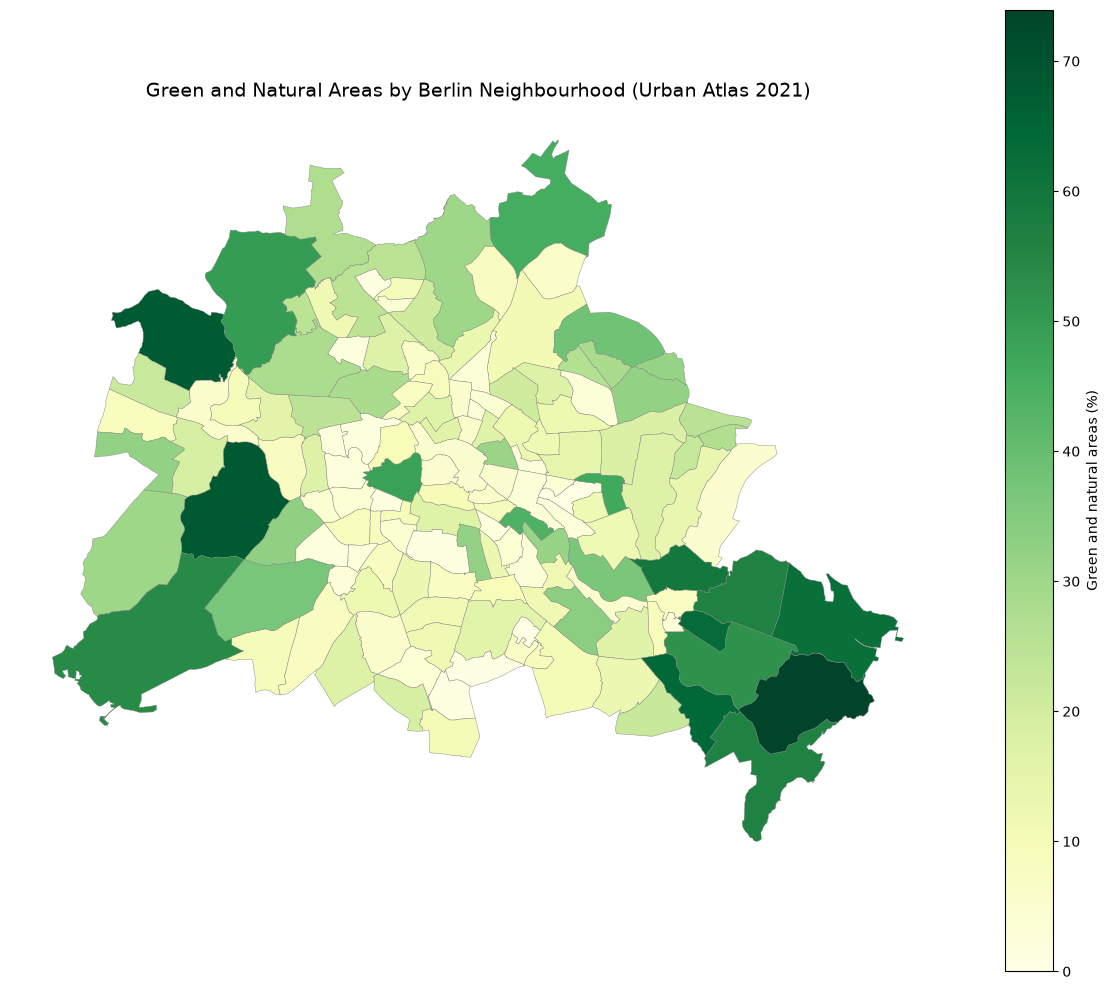

In [43]:
# Create the map
fig, ax = plt.subplots(figsize=(12, 10))

lor_land_cover.plot(
    column="green_natural",
    cmap="YlGn",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={
        "label": "Green and natural areas (%)",
        "orientation": "vertical"
    },
    ax=ax
)

# Add title and remove axes
ax.set_title(
    "Green and Natural Areas by Berlin Neighbourhood (Urban Atlas 2021)",
    fontsize=14
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

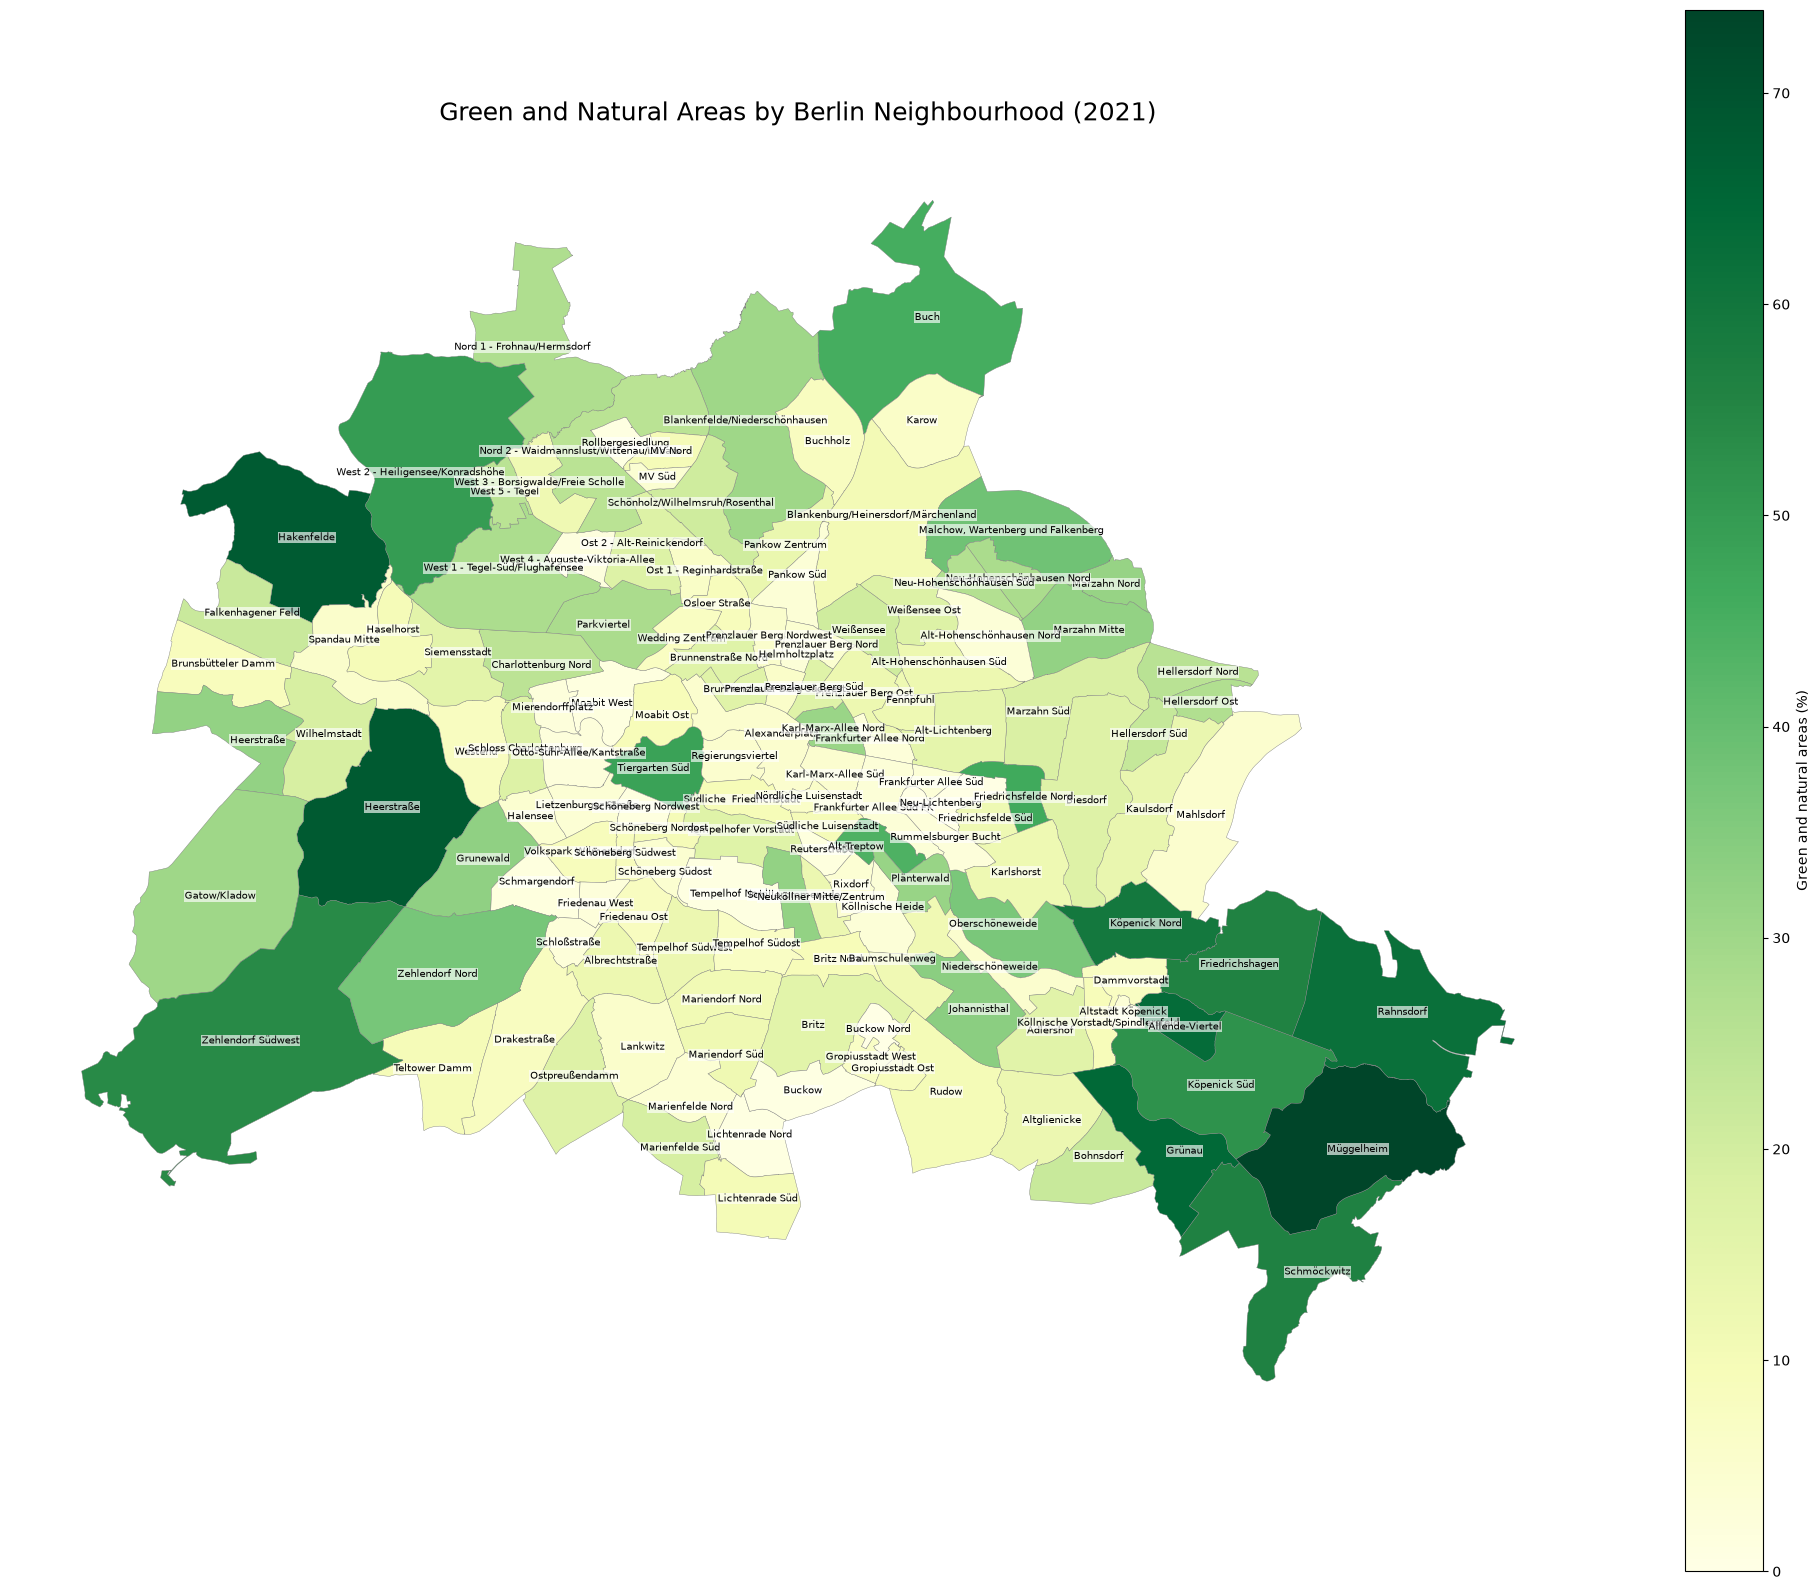

In [44]:
#creating the map showing kiez names

# Calculate one label position inside each neighbourhood
label_points = lor_land_cover.geometry.representative_point()

# Create the figure
fig, ax = plt.subplots(figsize=(20, 16))

# Plot green and natural areas
lor_land_cover.plot(
    column="green_natural",
    cmap="YlGn",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={
        "label": "Green and natural areas (%)",
    },
    ax=ax
)

# Add neighbourhood labels
for index, row in lor_land_cover.iterrows():
    ax.annotate(
        text=row["bzr_name"],
        xy=(label_points.loc[index].x, label_points.loc[index].y),
        ha="center",
        va="center",
        fontsize=7,
        color="black",
        bbox=dict(
            facecolor="white",
            alpha=0.65,
            edgecolor="none",
            pad=0.5
        )
    )

# Add title and remove axes
ax.set_title(
    "Green and Natural Areas by Berlin Neighbourhood (2021)",
    fontsize=18,
    pad=15
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [53]:
lor_land_cover.columns

Index(['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt',
       'stand', 'geometry', 'urban_fabric', 'green_natural',
       'industrial_commercial', 'transport_infrastructure', 'water_wetlands',
       'Arable land (annual crops)', 'Complex and mixed cultivation patterns',
       'Construction sites', 'Isolated structures', 'Land without current use',
       'Mineral extraction and dump sites',
       'Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)',
       'Sports and leisure facilities'],
      dtype='str')

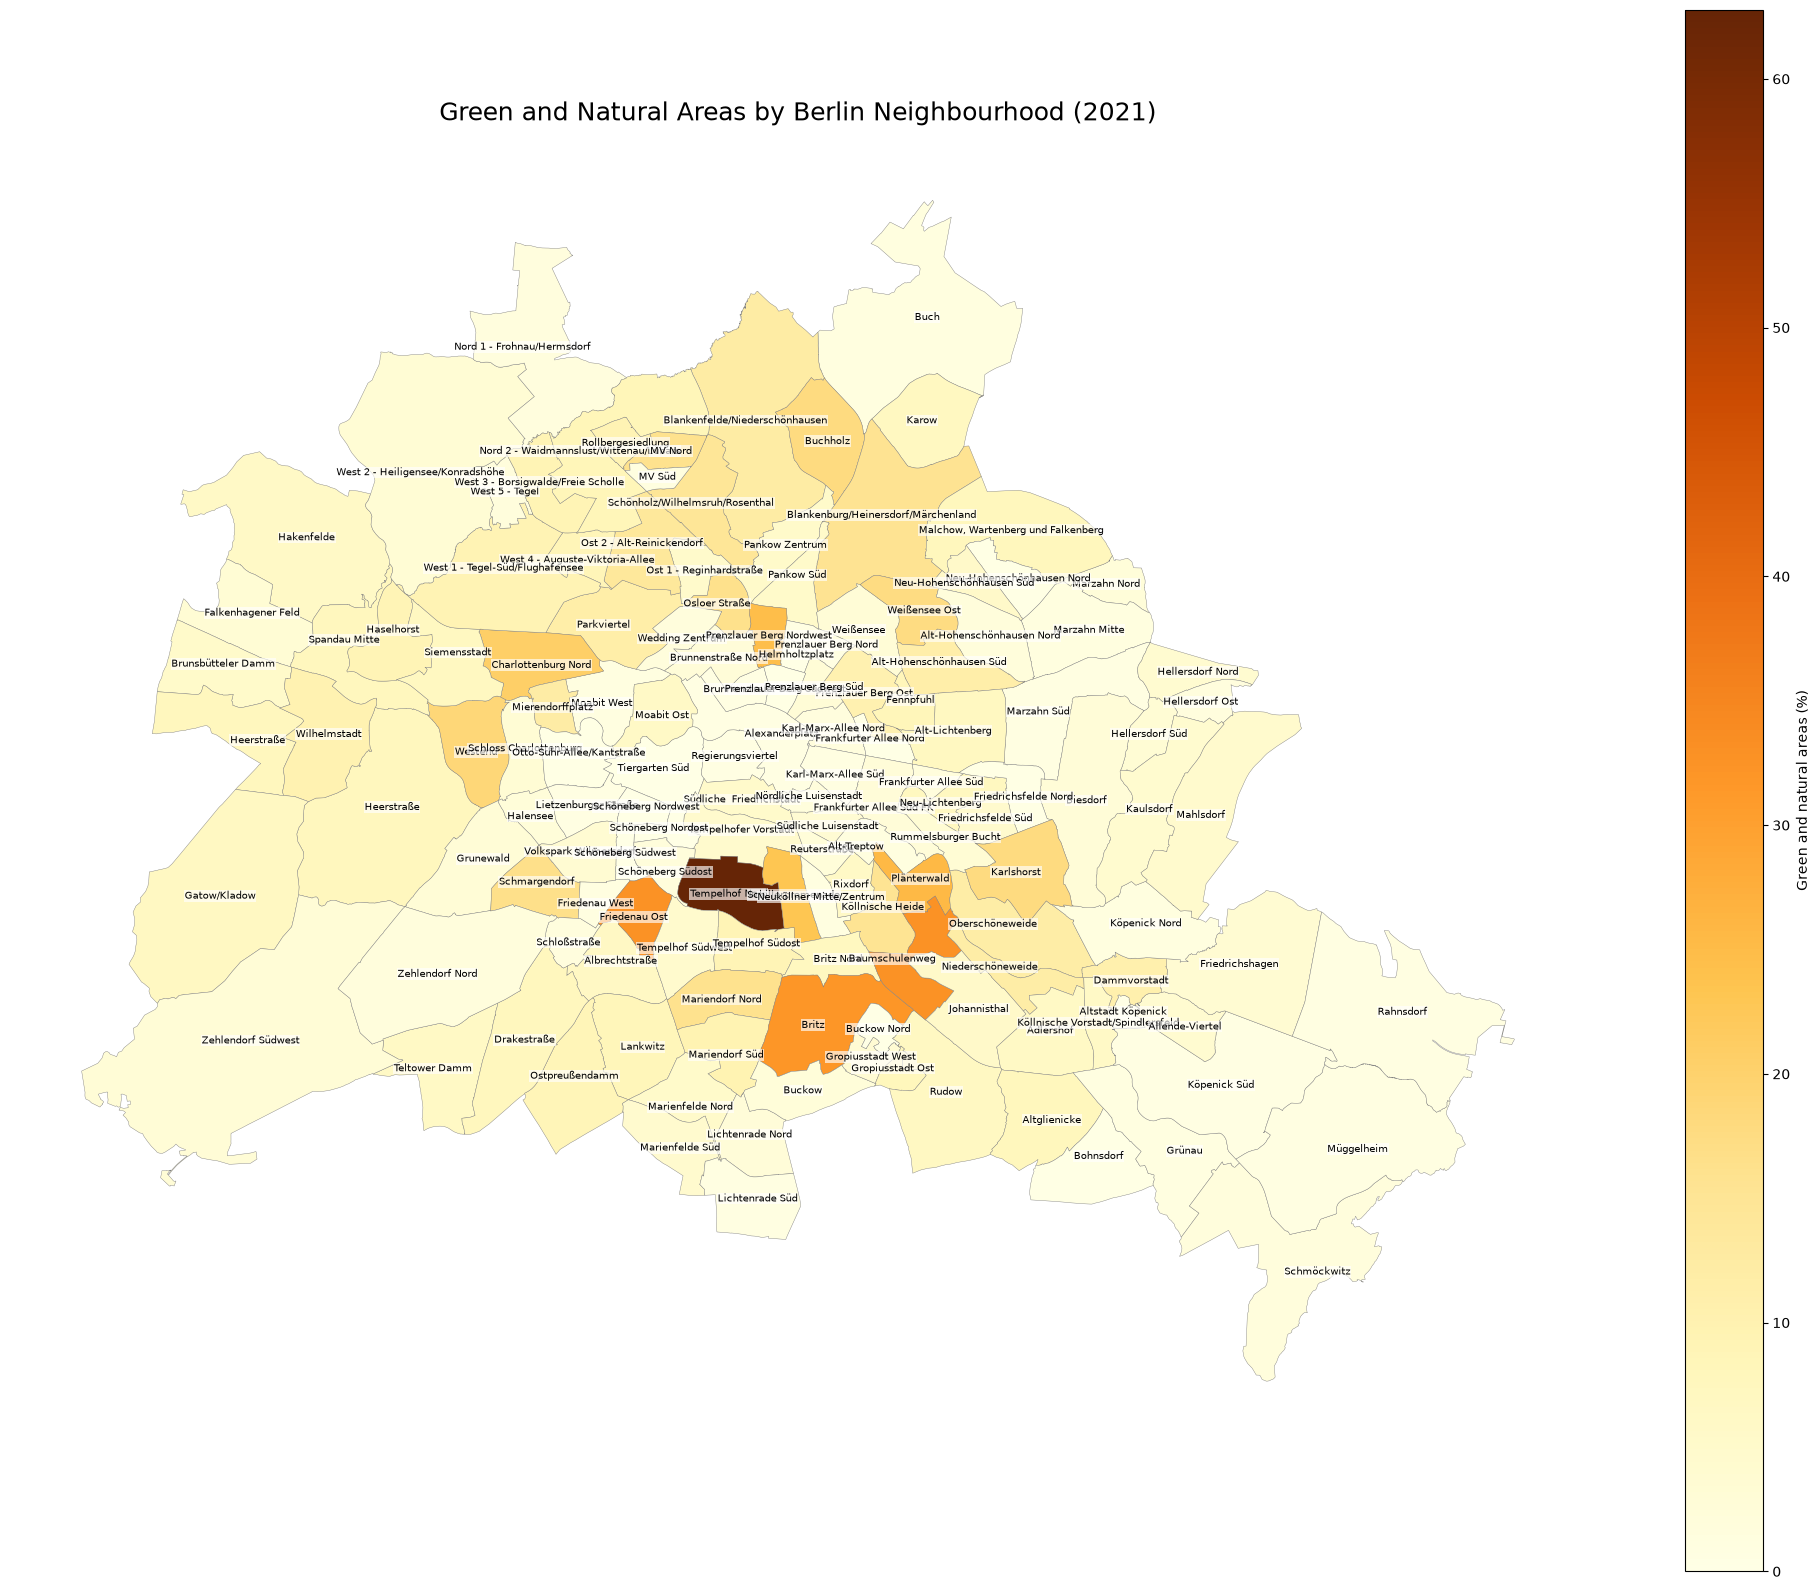

In [62]:
# Calculate one label position inside each neighbourhood
label_points = lor_land_cover.geometry.representative_point()

# Create the figure
fig, ax = plt.subplots(figsize=(20, 16))

# Plot green and natural areas
lor_land_cover.plot(
    column="Sports and leisure facilities",
    cmap="YlOrBr",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={
        "label": "Green and natural areas (%)",
    },
    ax=ax
)

# Add neighbourhood labels
for index, row in lor_land_cover.iterrows():
    ax.annotate(
        text=row["bzr_name"],
        xy=(label_points.loc[index].x, label_points.loc[index].y),
        ha="center",
        va="center",
        fontsize=7,
        color="black",
        bbox=dict(
            facecolor="white",
            alpha=0.65,
            edgecolor="none",
            pad=0.5
        )
    )

# Add title and remove axes
ax.set_title(
    "Green and Natural Areas by Berlin Neighbourhood (2021)",
    fontsize=18,
    pad=15
)
ax.set_axis_off()

plt.tight_layout()
plt.show()